# v002 shaft stepped gear: AxisForge shaft FEM with gear loads against r01, the gear identities and Harris

**Question.** Does `RigidSupportFEMSolver` reproduce the closed-form stepped beam (r01) of two stepped S355 shafts
(L 200 mm, d 20/28/25/28/20 mm, pins at 10 / 190 mm) loaded by a cylindrical pair at mid-span (m_n 2 mm, z 20/40,
T 100 N.m) exactly as `Transmission.resolve` produces the loads (F_c, F_t, F_a, torque, couple F_a r_w), with
prescribed pin settlements? Are the mesh loads themselves right?

**Judges.** r01 `solve_stepped` + the rigid-body field of the settlements; the gear inputs (ISO 21771) and the
statics of the pitch point; Harris2007_vol2 Eqs 9.24-9.27 (PDF p. 281). No stepped-shaft table is held.

**Criteria (README 6, fixed before the run).** EB nodal v, theta and every reaction within 1e-9 of r01 (C1-C3);
one-point Timoshenko equal to r01 at the per-segment kGA_eff within 1e-9 (C4, point loads); Richardson EB flat,
Timoshenko extrapolated within 1e-9 (C5, C6); gear identities 1e-12 (I1-I6) and the `Transmission` closure (I7);
Harris 1e-9 (L1-L5). **Every number that depends on the helical couple is convention-dependent (J-16).**

In [1]:
from IPython.display import Image, display
from axisforge.outputs._format import format_table

from studies.v000_axisforge.v002_shaft_stepped_gear import study

out = study.run()
fig = {p.stem.split("_", 2)[2]: p for p in out["figures"]}        # v002_<model file>_<function>[_<variant>]

## 1. Deflection and rotation along shaft1, 40 elements, base settlements
Filled markers: AxisForge nodes; lines: r01 + settlement field. Grey lines: section steps; dash-dot: the gear.
EB markers sit on their line; one-point Timoshenko markers sit slightly inside (too stiff, O(h^2)). The rotation
has a kink at the gear (the couple) and steeper slopes on the thinner gear seat.

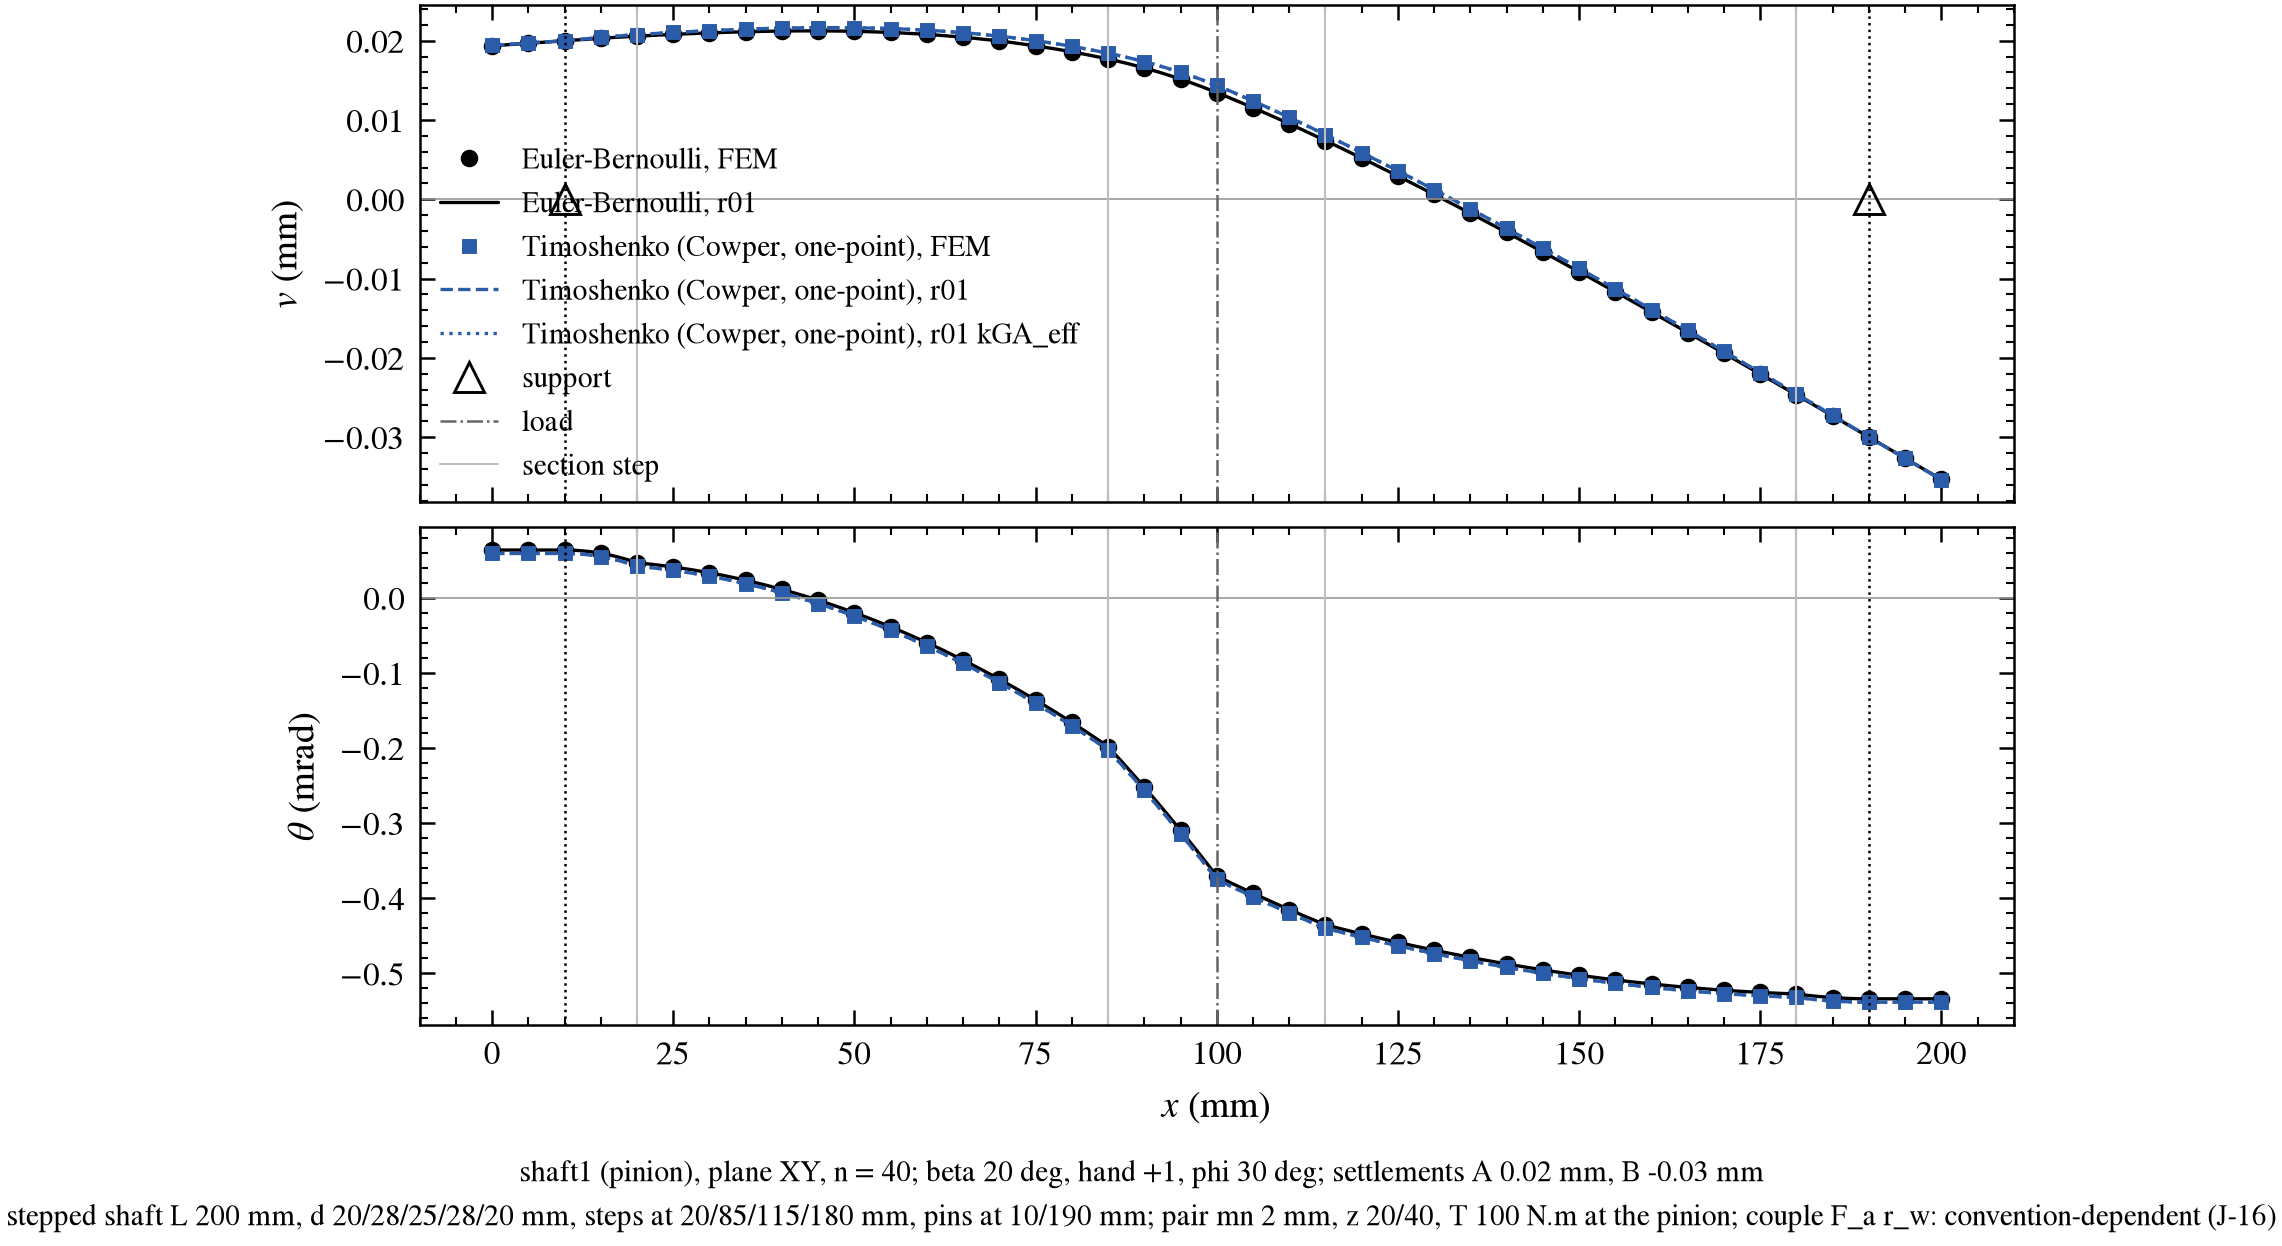

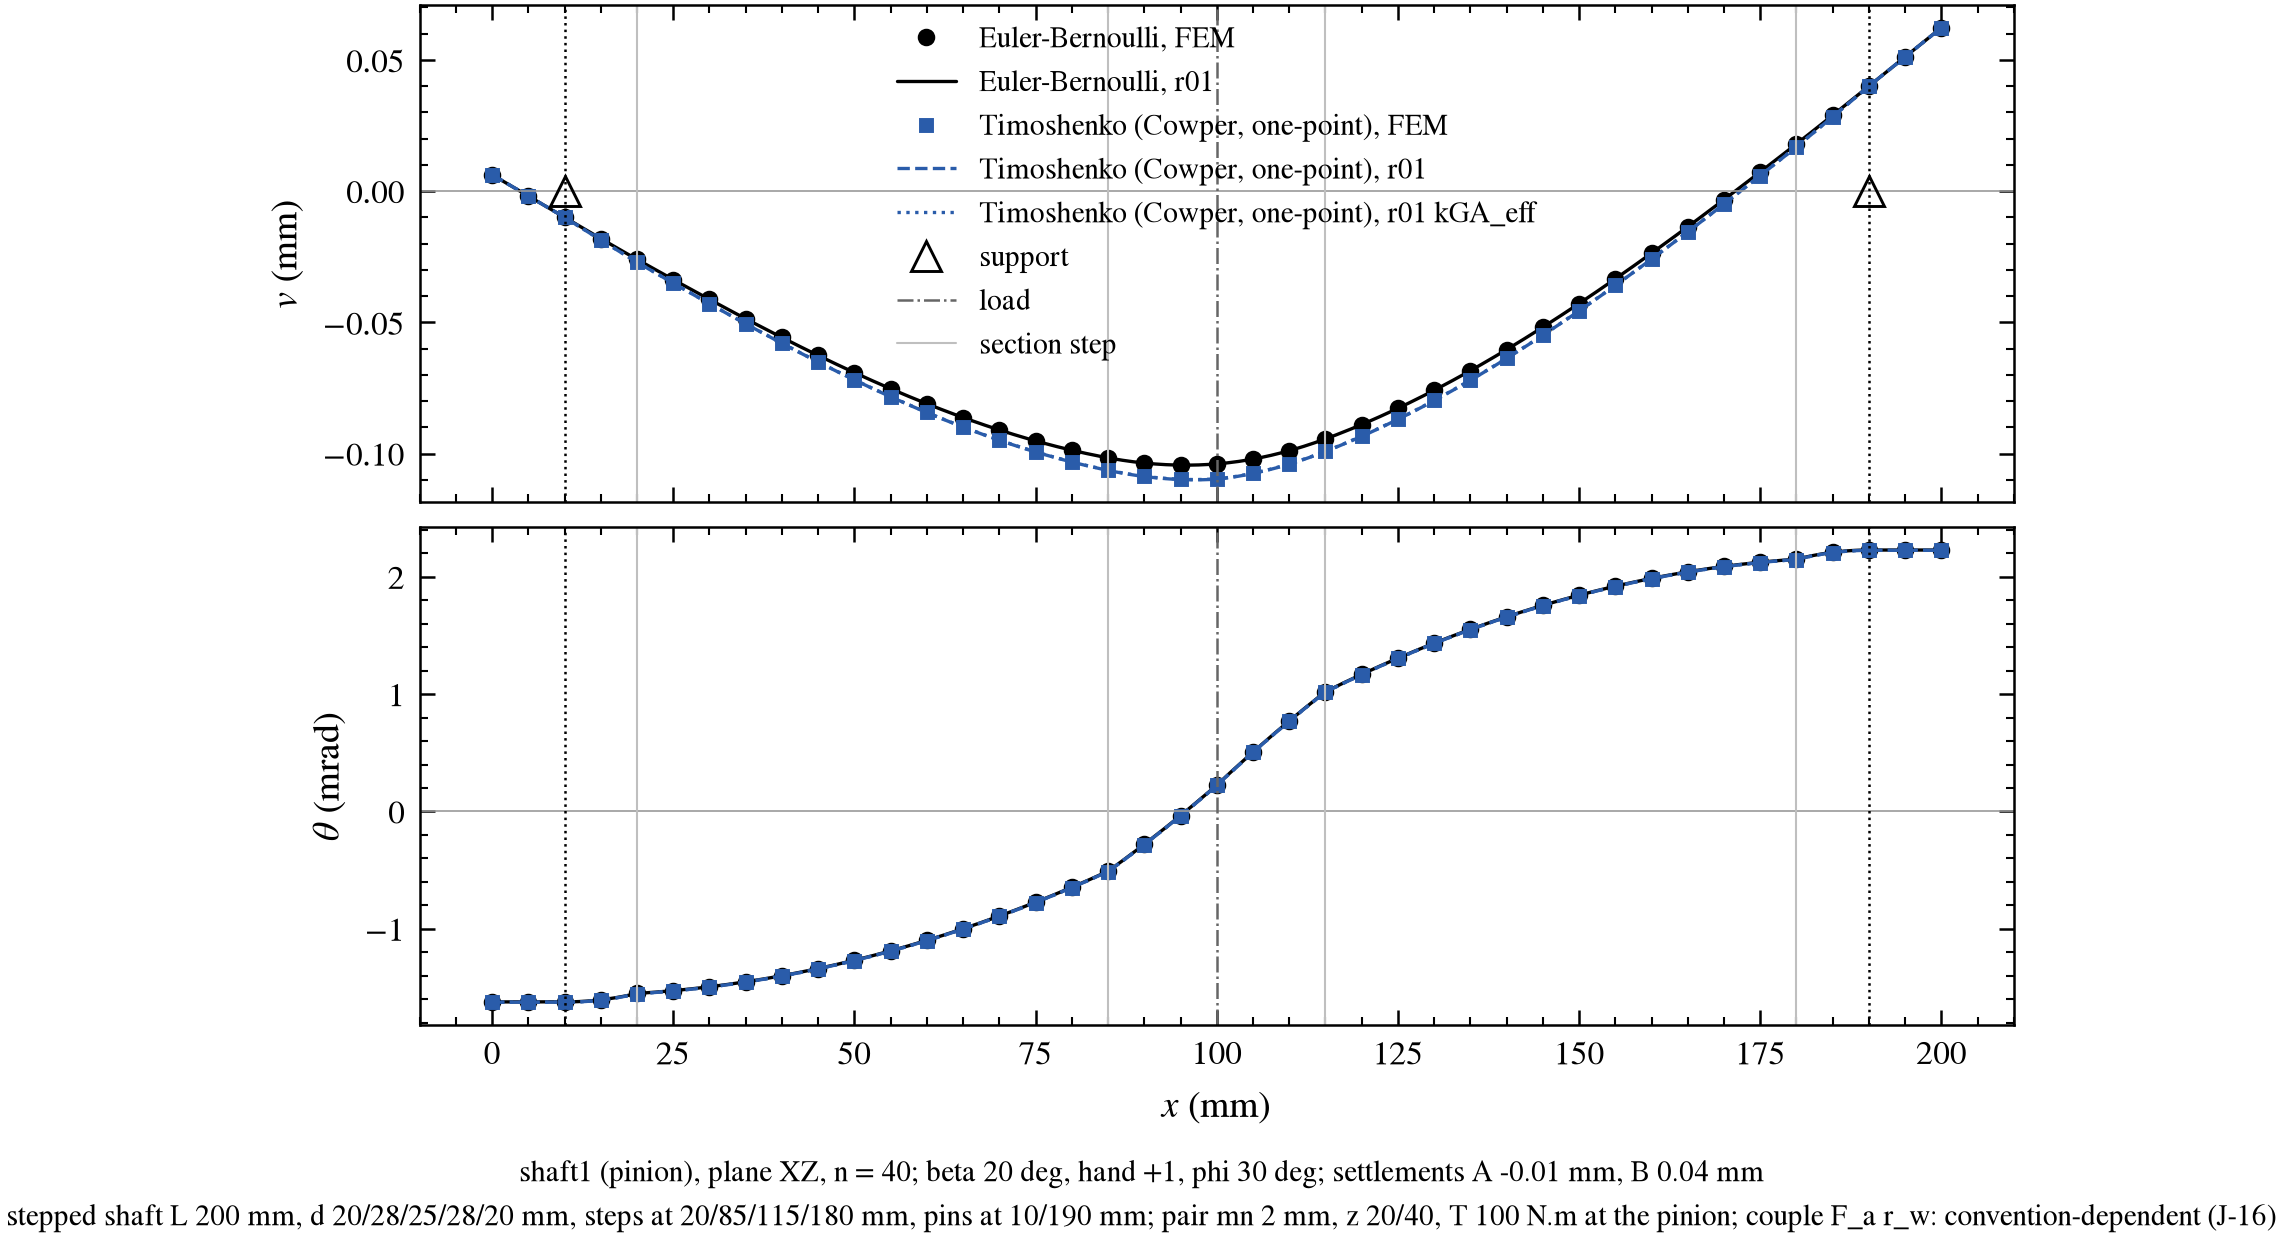

In [2]:
display(Image(filename=str(fig["deflection_along_shaft_XY_n40"])))
display(Image(filename=str(fig["deflection_along_shaft_XZ_n40"])))

## 2. Error against the number of elements and the Richardson series (v_xy at the gear, shaft1)
EB is nodally exact in exact arithmetic; in float64 its stiffness has cond ~ (L/h)^4 (x16 per halving), so the
round-off grows x8 per halving and passes 1e-9 at n = 320 (MISS, README 8, R5-33: conditioning, not a defect);
the one-point Timoshenko element at kGA_eff stays at 1e-12 and its error against r01 at kGA falls as h^2.

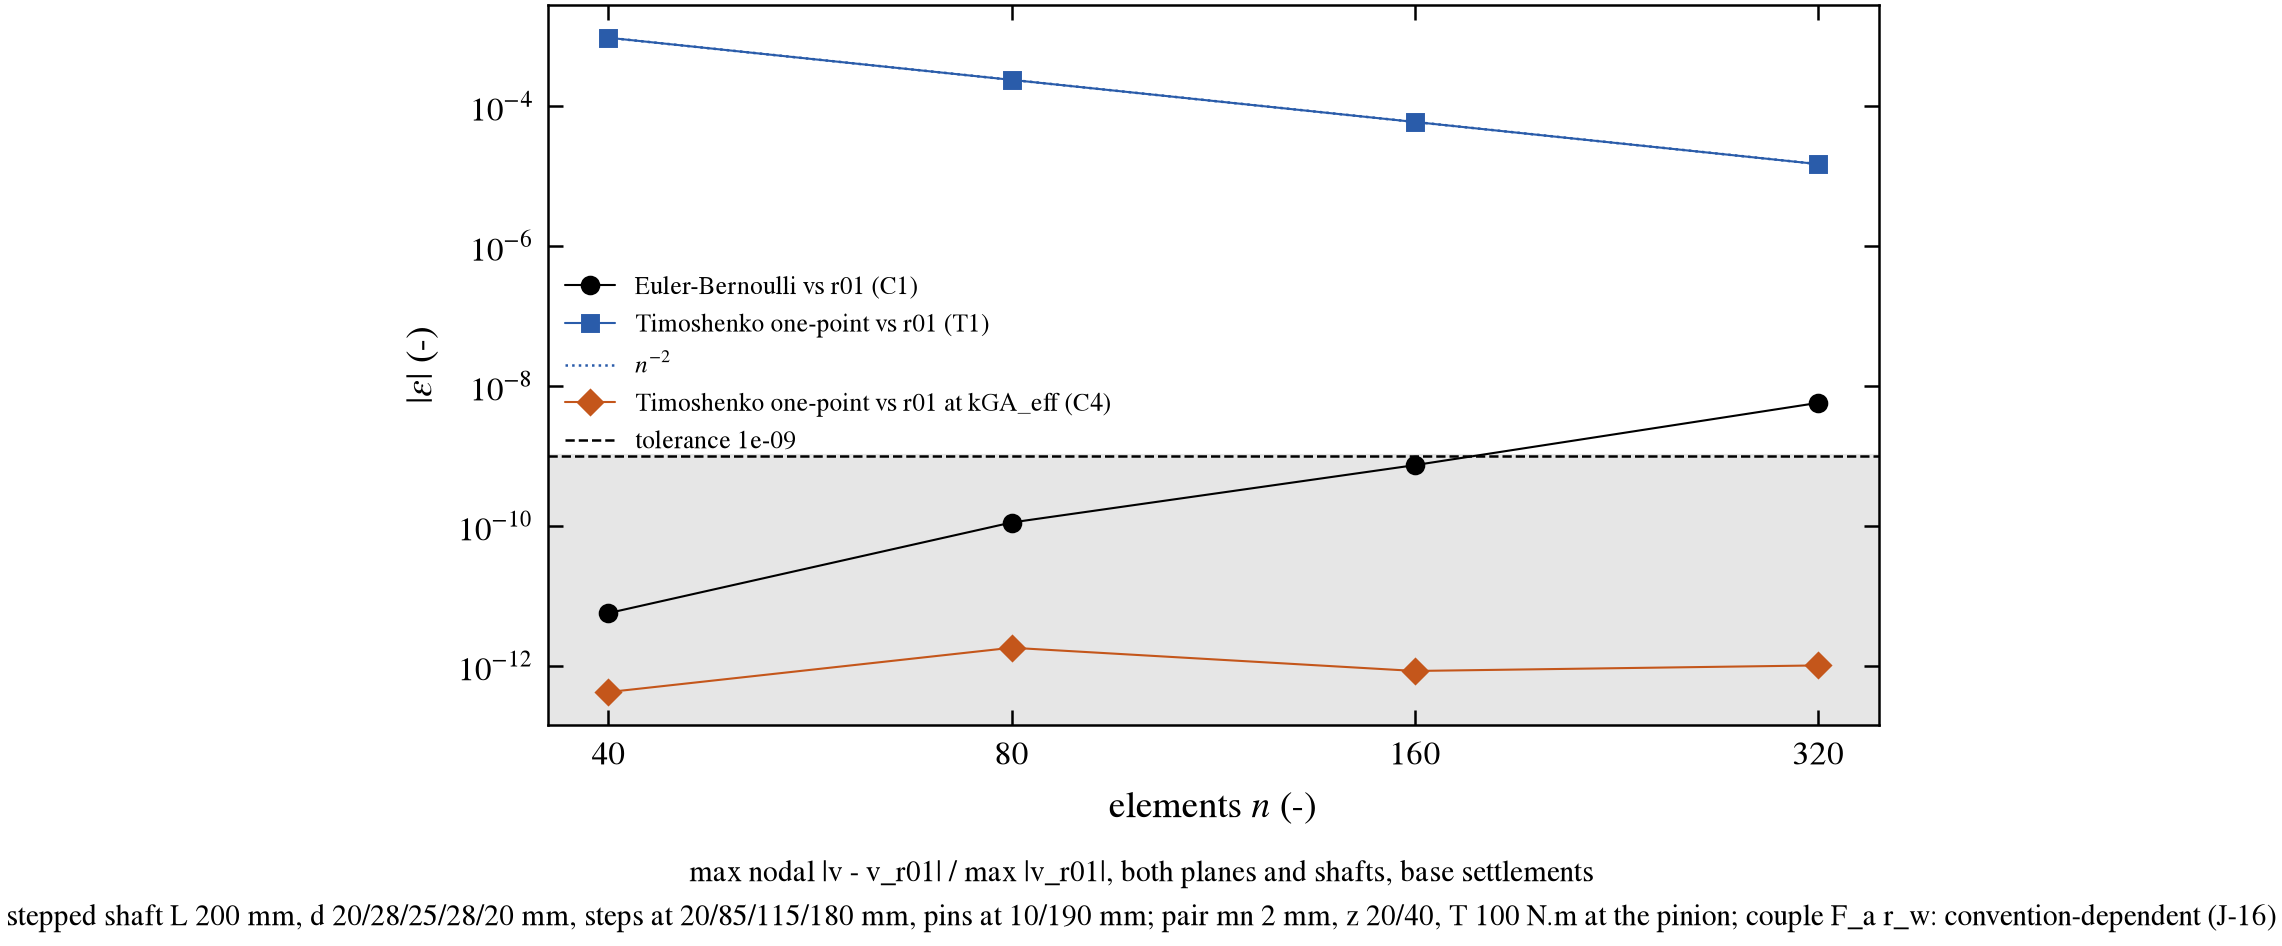

                            theory    n          v [mm]     status         p  extrapolated [mm]    GCI fm        r01 [mm]
----------------------------------  ---  --------------  ---------  --------  -----------------  --------  --------------
                   euler_bernoulli   40  0.013466903944                    -                  -         -  0.013466903944
                   euler_bernoulli   80  0.013466903946                    -                  -         -  0.013466903944
                   euler_bernoulli  160  0.013466903946       flat         -     0.013466903946  0.00e+00  0.013466903944
                   euler_bernoulli  320  0.013466903977       flat         -     0.013466903977  0.00e+00  0.013466903944
    timoshenko/cowper/single_point   40  0.014357706235                    -                  -         -  0.014373852200
    timoshenko/cowper/single_point   80  0.014369815709                    -                  -         -  0.014373852200
    timoshenko/cowper/si

In [3]:
display(Image(filename=str(fig["error_vs_elements"])))
print(format_table((("theory", "theory", "s"), ("level", "n", ".0f"), ("value", "v [mm]", ".12f"),
                    ("status", "status", "s"), ("p", "p", ".6f"), ("f_extrapolated", "extrapolated [mm]", ".12f"),
                    ("gci_fine_medium", "GCI fm", ".2e"), ("r01_v_gear_xy_mm", "r01 [mm]", ".12f")), out["richardson"]))
print(format_table((("label", "shaft", "s"), ("theory", "theory", "s"), ("n_elements", "n", ".0f"), ("plane", "plane", "s"),
                    ("id", "id", "s"), ("quantity", "q", "s"), ("rel_err", "rel err", ".2e"), ("verdict", "verdict", "s")),
                   [r for r in out["check"] if r["verdict"] == "MISS"]))

## 3. Settlements and helix angle / hand: error along the sweep (limits: delta = 0 rigid pins, beta = 0 spur)

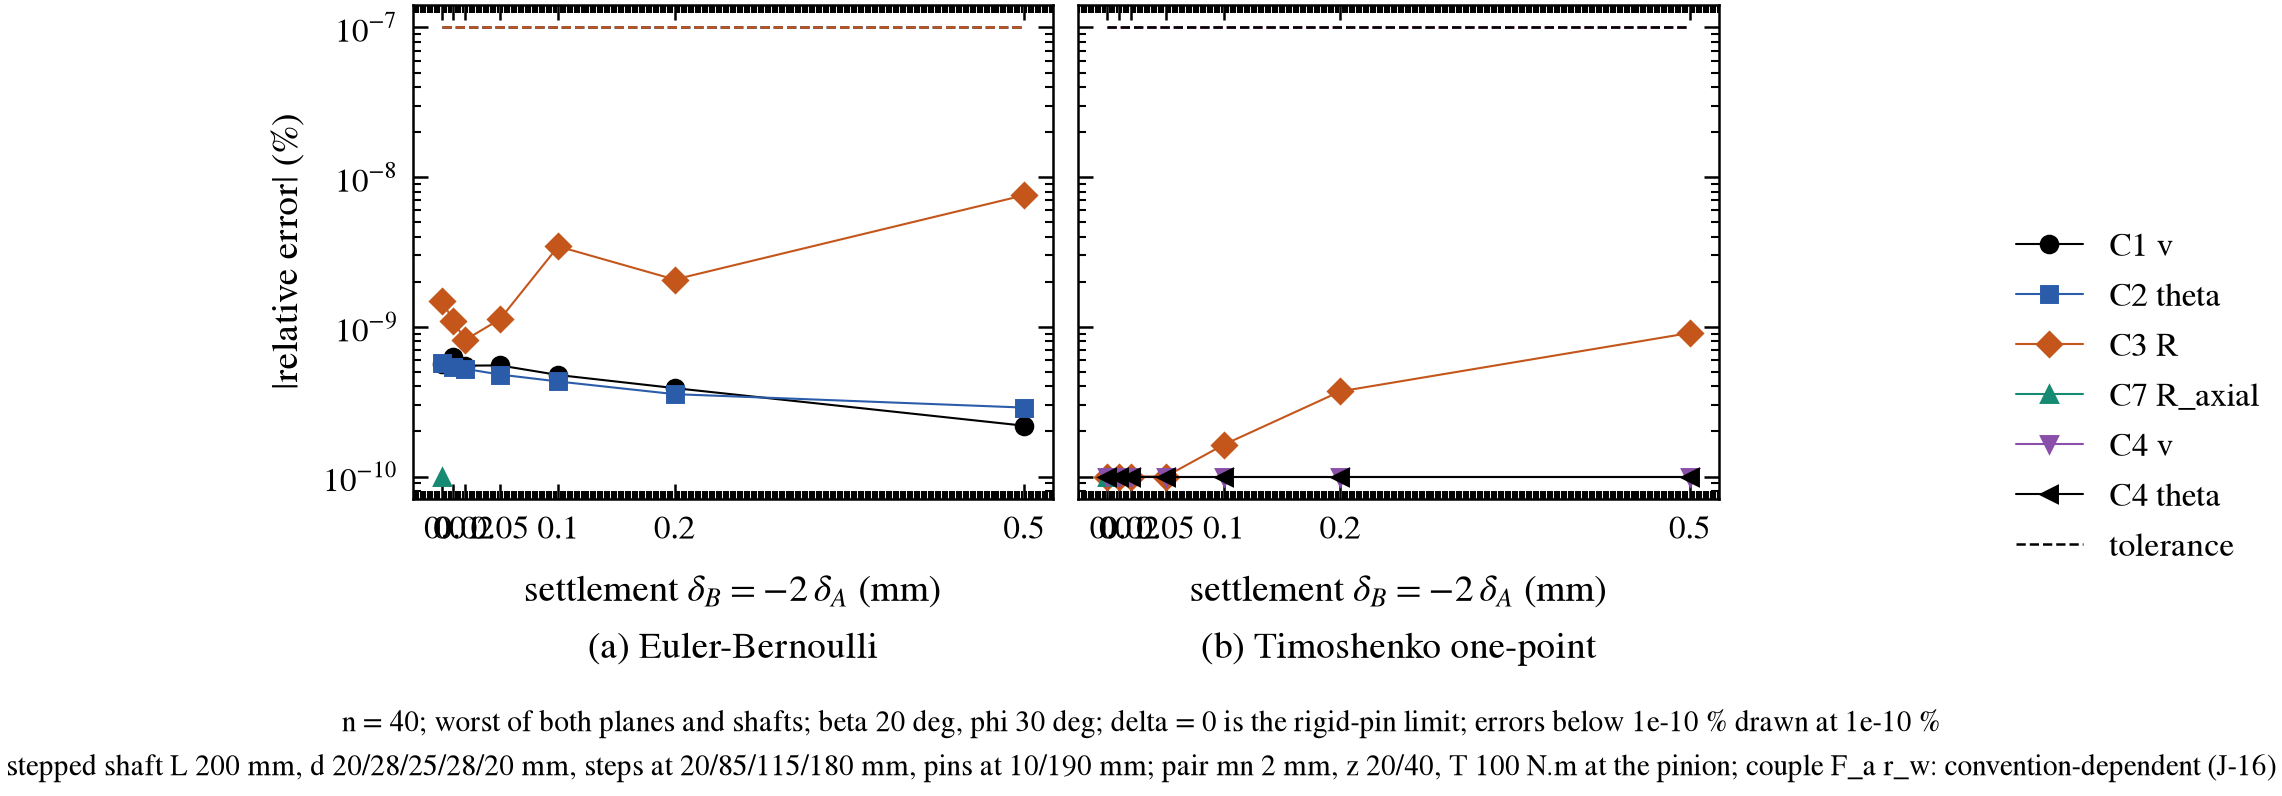

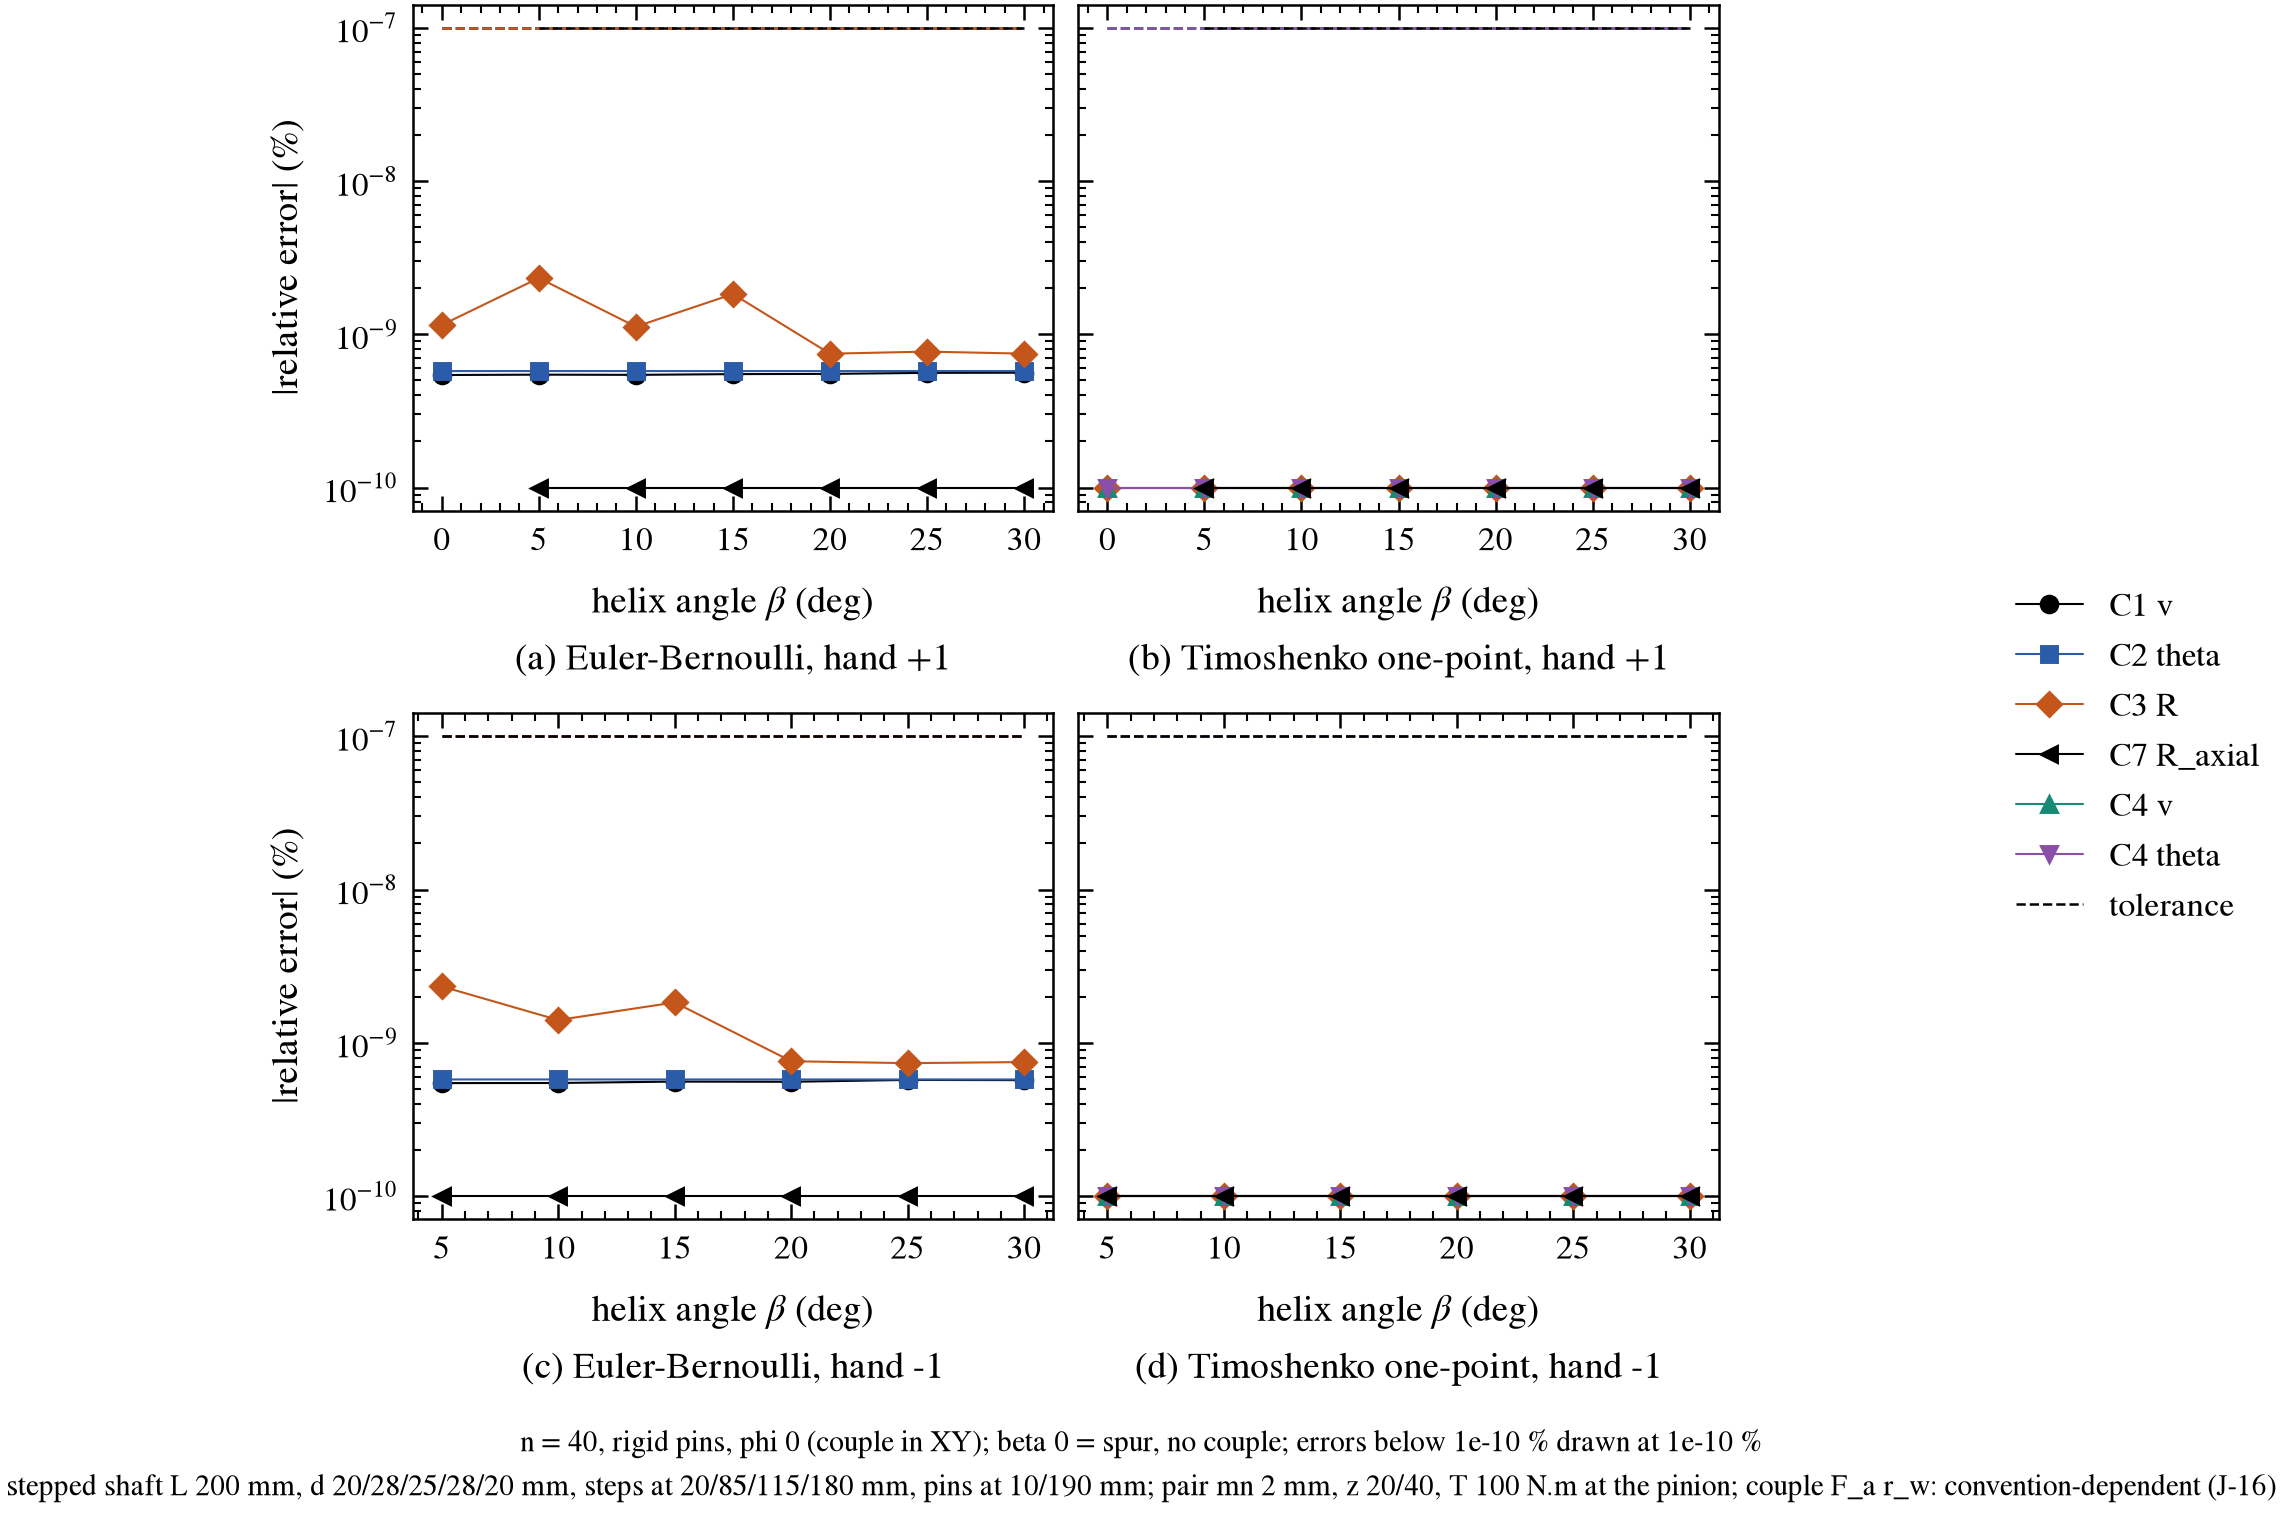

In [4]:
display(Image(filename=str(fig["relative_errors_settlement"])))
display(Image(filename=str(fig["relative_errors_helix"])))

## 4. The couple F_a r_w: its share of the reaction at pin A (J-16)
FEM minus r01 without the couple, over F_tw r_w / span: on the statics line +-tan(beta), the sign set by the hand.

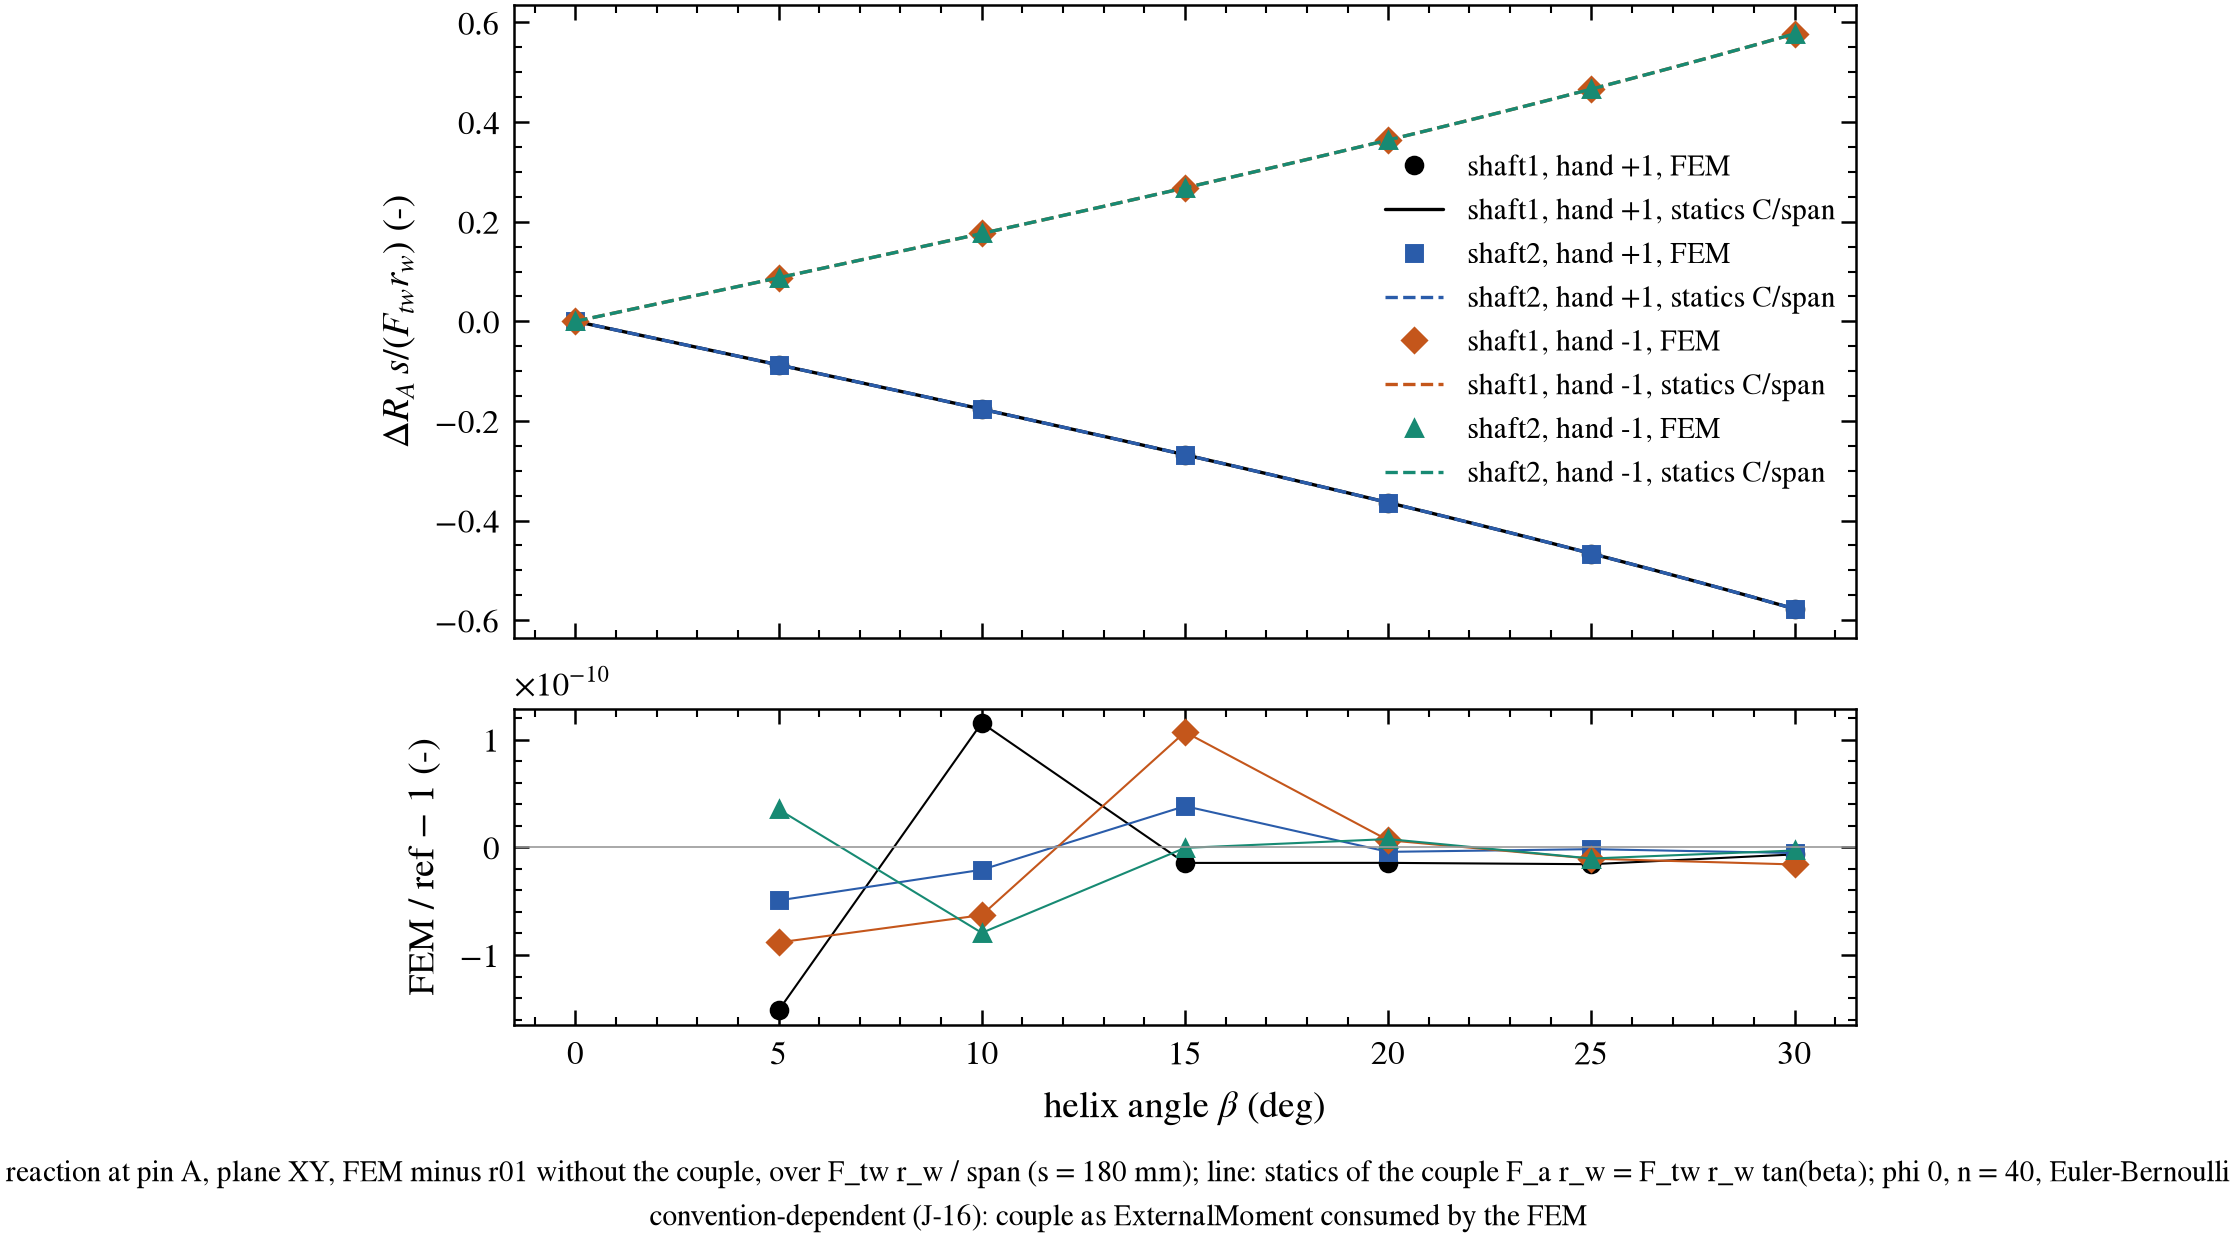

In [5]:
display(Image(filename=str(fig["ratio_sweep_couple_shift"])))

## 5. Gear-load identities (base: beta 20 deg, hand +1, phi 30 deg)
The judge is built from the inputs (`mesh_judge`: signs from hand, rotation and driver). I3s, I8: the signed axial
force on the gear and on the shaft; I5: the couple the FEM consumes equals r x F; T5: the reading by the names `My`,
`Mz` would not (CW-01).

In [6]:
print(format_table((("shaft", "shaft", "s"), ("id", "id", "s"), ("quantity", "quantity", "s"), ("value", "value", ".6g"),
                    ("judge", "judge", ".6g"), ("rel_err", "rel err", ".2e"), ("verdict", "verdict", "s")),
                   [r for r in out["identities"] if r.get("sweep") == "base"]))

       shaft   id                                                       quantity        value    judge   rel err  verdict
------------  ---  -------------------------------------------------------------  -----------  -------  --------  -------
        mesh   I1                                                           F_tw      4698.46  4698.46  1.94e-16     PASS
        mesh   I2                                                            F_r      1819.85  1819.85  3.39e-16     PASS
        mesh   I3                                                            F_a       1710.1   1710.1  9.68e-17     PASS
        mesh  I3s                                                   F_1,x signed       1710.1   1710.1  9.68e-17     PASS
      shaft1   I4                                        transverse force (Y, Z)      5038.59  5038.59  1.94e-16     PASS
      shaft1   I8                                           AxialLoad sum vs F_x       1710.1   1710.1  9.68e-17     PASS
      shaft1   I5       

## 6. Harris2007_vol2 sec. 9.2.2: Eqs 9.24-9.27 at the FEM slopes (L1-L5); the printed 1/l^3 of Eqs 9.25, 9.27 (L6)

In [7]:
print(format_table((("id", "id", "s"), ("quantity", "quantity", "s"), ("measured", "FEM", ".9g"),
                    ("reference", "Harris", ".9g"), ("rel_err", "rel err", ".2e"), ("verdict", "verdict", "s")),
                   [r for r in out["literature"] if r["id"].startswith("L")]))

id                        quantity             FEM          Harris   rel err  verdict
--  ------------------------------  --------------  --------------  --------  -------
L1                      F_1 = -R_A      2188.88889      2188.88889  1.56e-12     PASS
L2                      F_2 = -R_B      311.111111      311.111111  4.12e-12     PASS
L3  M_1 at the FEM slopes (pin: 0)               0  3.16067599e-08  2.22e-13     PASS
L4  M_2 at the FEM slopes (pin: 0)               0   1.2597593e-07  8.83e-13     PASS
L5                   theta_1 (pin)   0.00080490891   0.00080490891  8.72e-13     PASS
L5                   theta_2 (pin)  -0.00102666237  -0.00102666237  1.31e-12     PASS
L6          M_1 as printed (1/l^3)               0     -91111.3683  6.39e-01   RECORD
L6          M_2 as printed (1/l^3)               0     -14134.0021  9.91e-02   RECORD


## 7. Verdict

In [8]:
rows = out["check"] + out["identities"] + [r for r in out["literature"] if r["id"].startswith("L")]
judged = [r for r in rows if r["verdict"] != "RECORD"]
print(f"judged {len(judged)}, PASS {sum(r['verdict'] == 'PASS' for r in judged)}, "
      f"MISS {sum(r['verdict'] == 'MISS' for r in judged)}")

judged 1324, PASS 1313, MISS 11
